# Experimentación por familias de variables

**Qué decide esta notebook:** qué familias de variables usa el **Ridge**, el modelo de caja de cristal. Va **antes**
del modelo final: el producto es el modelo, y esta notebook justifica con qué información se entrena.
**LightGBM**, la caja negra, recibe siempre las 8 familias. La pregunta del producto es si una caja negra con toda
la información es sustancialmente mejor que un modelo regularizado y legible. Los dos modelos finales se comparan
después contra el NWS crudo y los baselines (`comparacion_modelos.ipynb`).

**Recorrido**, una sección por familia (1 a 8):
1. **Hipótesis experta:** por qué la familia podría corregir el error del NWS, desde la meteorología.
2. **Exploración:** correlación de cada variable con el error del NWS, por horizonte, y boxplots del error.
3. **Ridge con todas las familias:** cuánto aporta cada familia a la predicción y si ese aporte es estable entre pliegues.
4. **Ridge sin cada familia (ablación)** y **regla de recorte fijada de antemano**.

**Datos:** congelados al **09/11/2026** (`experimentos.fecha_corte` en `config.yaml`). Los días posteriores no
reabren los experimentos.

**Qué días se usan para decidir:** solo los de los **pliegues de elección** (1 y 2). La exploración usa solo días
hasta el final del último bloque de prueba de elección. Ningún día de prueba de los pliegues de reporte (3 en
adelante) interviene: si interviniera, la decisión «ya habría visto» la respuesta y el error final quedaría optimista.

**Error:** `error_c = observado − pronosticado` (°C). **MAE:** error absoluto medio de la temperatura corregida,
en °C, en días con historia completa y filas con observación real.

Salidas: tablas en `salidas/experimentos/` y figuras en `salidas/experimentos/figuras/` (versionadas). La caché
pesada queda en `data/cache/` (no versionada): volver a correr la notebook sin cambios en los datos tarda minutos.

In [1]:
import sys
from pathlib import Path

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from IPython.display import Image, display

import experimentos as E
import modelo_interpretable as MI
from interpretar import SERIE, TXT2, GRILLA, estilo

estilo()
FIG = E.SALIDA / "figuras"
FIG.mkdir(parents=True, exist_ok=True)
DIVERGENTE = LinearSegmentedColormap.from_list("div", [SERIE[0], "#f0efeb", SERIE[1]])
SECUENCIAL = LinearSegmentedColormap.from_list("seq", ["#f0efeb", SERIE[0]])
pd.set_option("display.precision", 3)


def guardar(fig, nombre):
    # guarda en salidas/experimentos/figuras/ y muestra el PNG (interpretar.py fija el backend Agg)
    fig.savefig(FIG / nombre, dpi=160, bbox_inches="tight")
    plt.close(fig)
    display(Image(filename=str(FIG / nombre)))


eleccion, reporte = E.pliegues()
tabla = pd.DataFrame([{"pliegue": k, "uso": "elige", "entrena": f"{tr.min():%d/%m} → {tr.max():%d/%m} ({len(tr)} días)",
                       "prueba": f"{te.min():%d/%m} → {te.max():%d/%m}"} for k, (tr, te) in eleccion]
                     + [{"pliegue": k, "uso": "reporta (no se mira acá)", "entrena": f"{tr.min():%d/%m} → {tr.max():%d/%m} ({len(tr)} días)",
                         "prueba": f"{te.min():%d/%m} → {te.max():%d/%m}"} for k, (tr, te) in reporte]).set_index("pliegue")
dias_exp = E.dias_exploracion()
print(f"Corte de los experimentos: {E.CORTE:%d/%m/%Y}. Días de exploración: {len(dias_exp)} "
      f"({dias_exp.min():%d/%m} → {dias_exp.max():%d/%m}).")
display(tabla)

Corte de los experimentos: 09/11/2026. Días de exploración: 30 (10/09 → 09/10).


,uso,entrena,prueba
pliegue,,,
1,elige,10/09 → 27/09 (18 días),30/09 → 04/10
2,elige,10/09 → 02/10 (23 días),05/10 → 09/10
3,reporta (no se mira acá),10/09 → 07/10 (28 días),10/10 → 14/10
4,reporta (no se mira acá),10/09 → 13/10 (34 días),16/10 → 29/10
5,reporta (no se mira acá),10/09 → 29/10 (40 días),02/11 → 06/11


## Regla de recorte (fijada antes de ver los resultados, 17/11/2026)

Por cada familia se entrena un Ridge **sin ella**, con su propia búsqueda de α, en los pliegues de elección. La
familia **se saca** si se cumplen las dos condiciones:
1. sin ella, el MAE promedio de los pliegues de elección no empeora en más de **0,005 °C** respecto del Ridge con
   todas las familias;
2. en ningún pliegue de elección empeora en más de **0,010 °C**.

El Ridge final es «todas menos las que se sacan». Si sacarlas juntas empeora más de 0,005 °C (dos familias que, cada
una por separado, no hacían falta, pero sí juntas), se devuelve la de mayor costo y se repite. El aporte y la
estabilidad del paso 3 **explican** por qué una familia se va o se queda, pero no deciden. El grupo puede apartarse
de la regla solo dejando escrita la razón (celda `APARTARSE_DE_LA_REGLA`, al final).

**Por qué estos umbrales:**
- **Fijados antes de ver resultados (pre-registro).** Si el umbral se elige mirando las tablas, sin querer se termina
  eligiendo el que favorece el resultado esperado. Escrita antes, la regla se puede defender, la puede repetir un
  tercero y se aplica sola cuando lleguen datos nuevos.
- **0,005 °C es «no distinguible».** Es menos del 0,5 % del MAE (≈ 1,3 °C) y está por debajo del ruido entre días ya
  medido: con todas las familias experimentales, LightGBM mejoró 0,012 °C por día y no fue significativo
  (p = 0,12; DECISIONES.md). Una familia que cambia menos que eso no aporta nada detectable con estos datos y le
  resta legibilidad al modelo.
- **0,010 °C por pliegue** evita sacar una familia que en promedio no importa, pero que en un período concreto (por
  ejemplo, una semana con frentes) sí ayuda. Duplica el umbral promedio para tolerar el ruido de un solo pliegue.
- **El daño de elegir mal está acotado:** la decisión usa solo los pliegues de elección, y el error del informe se
  mide en los de reporte, que no intervienen.

## Exploración: muestra de los días de exploración

Medio millón de filas con observación real, al azar (semilla fija), de los días de exploración. La correlación es la
de **Spearman** (por rangos: no supone una relación lineal y no la dominan los valores extremos). Una correlación con
el error del NWS indica que la variable *podría* ayudar a corregirlo. No lo garantiza: puede repetir lo que ya dice
otra familia.

In [2]:
muestra = E.muestra_exploracion()
corr = E.correlaciones(muestra)
E.exportar("correlaciones_con_el_error", corr, index=False)
print(f"{len(muestra):,} filas de {muestra.station_id.nunique()} estaciones".replace(",", "."))

HORIZ = ["total", "h1", "h6", "h24", "h48"]
ETIQ = {"total": "todos", "h1": "1 h", "h6": "6 h", "h24": "24 h", "h48": "48 h"}


def explorar(familia, principal, titulo_x):
    """Tabla de correlaciones de la familia, barras por horizonte y boxplot del error por quintiles de la variable principal."""
    c = corr[corr.familia == familia].set_index("variable")
    display(c[["faltantes_pct"] + HORIZ].rename(columns=ETIQ).round(3))
    fig, ax = plt.subplots(1, 2, figsize=(11, max(2.4, 0.32 * len(c) + 1)), gridspec_kw={"width_ratios": [1.1, 1]})
    y = np.arange(len(c))
    for j, h in enumerate(["h1", "h6", "h24", "h48"]):
        ax[0].barh(y + (j - 1.5) * 0.2, c[h], height=0.18, color=SERIE[j], label=ETIQ[h])
    ax[0].set(yticks=y, yticklabels=c.index, xlabel="correlación de Spearman con el error del NWS",
              title="Correlación con el error, por horizonte")
    ax[0].axvline(0, color=TXT2, lw=0.8)
    ax[0].invert_yaxis()
    ax[0].legend(loc="lower right", fontsize=8)
    x = muestra[[principal, "error_c"]].dropna()
    q = pd.qcut(x[principal], 5, duplicates="drop")
    grupos = [g["error_c"].to_numpy() for _, g in x.groupby(q, observed=True)]
    ax[1].boxplot(grupos, showfliers=False, widths=0.5, patch_artist=True,
                  boxprops=dict(facecolor="#dbe8f7", edgecolor=SERIE[0]), medianprops=dict(color=SERIE[1], lw=2),
                  whiskerprops=dict(color=TXT2), capprops=dict(color=TXT2))
    ax[1].set_xticks(range(1, len(grupos) + 1), [f"{iv.left:.1f}\n{iv.right:.1f}" for iv in q.cat.categories], fontsize=7)
    ax[1].axhline(0, color=TXT2, lw=0.8)
    ax[1].set(xlabel=f"{titulo_x} (quintiles)", ylabel="error del NWS (°C)", title=f"Error del NWS según {principal}")
    fig.tight_layout()
    guardar(fig, f"exploracion_{familia}.png")

469.977 filas de 519 estaciones


## 1. Base: el pronóstico mismo

Variables: `temp_pron`, `temp_anom`, `elev_solar`, `noche`, `hum_pron`, `rocio_pron`, `dep_rocio`, `viento_vel`, `viento_sin`, `viento_cos`, `viento_calmo`, `prob_lluvia`, `condicion`, `horizonte`, `hora_solar_sin`, `hora_solar_cos`, `lat`, `lon`

**Hipótesis experta.** El NWS comete errores sistemáticos según la situación del tiempo:
- cerca de la saturación (depresión del rocío chica) la temperatura casi no puede bajar del punto de rocío, así que
  un pronóstico que la baja demasiado falla hacia arriba;
- con cielo despejado y viento calmo, de noche se forma una inversión por radiación que los modelos subestiman;
- el viento mezcla la capa cercana al suelo y achica esos extremos;
- la hora del día marca las transiciones de la mañana y la tarde, donde un error de horario pesa más.

**Qué esperamos ver:** el error cambia con la depresión del rocío, la condición, la noche y el viento.

,faltantes_pct,todos,1 h,6 h,24 h,48 h
variable,,,,,,
temp_pron,0.000,-0.045,-0.022,-0.025,-0.057,-0.074
temp_anom,9.476,0.046,0.019,0.037,0.044,0.057
elev_solar,0.000,0.111,0.154,0.129,0.105,0.087
noche,0.000,-0.134,-0.179,-0.146,-0.123,-0.123
hum_pron,0.022,0.082,0.064,0.066,0.080,0.123
rocio_pron,0.000,-0.016,-0.001,-0.010,-0.029,-0.018
dep_rocio,0.000,-0.084,-0.065,-0.067,-0.083,-0.124
viento_vel,0.000,0.079,0.084,0.084,0.090,0.037
viento_sin,0.000,-0.027,-0.013,-0.012,-0.020,-0.036


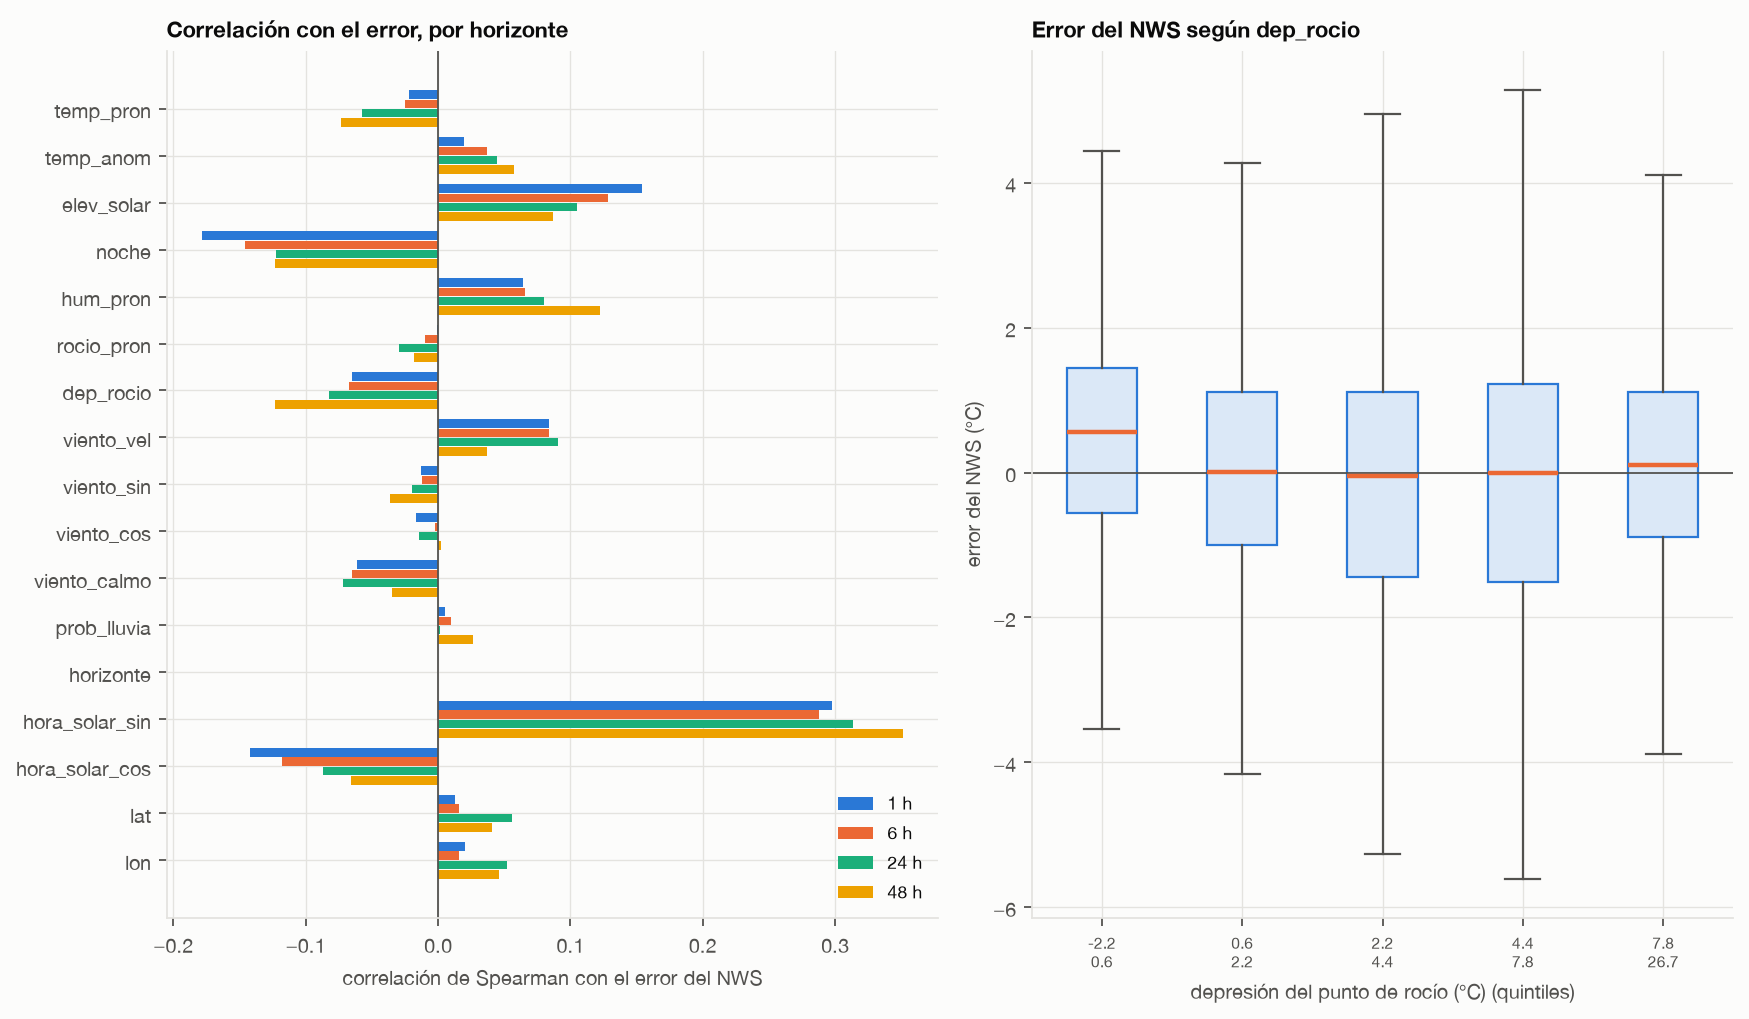

In [3]:
explorar("base", "dep_rocio", "depresión del punto de rocío (°C)")

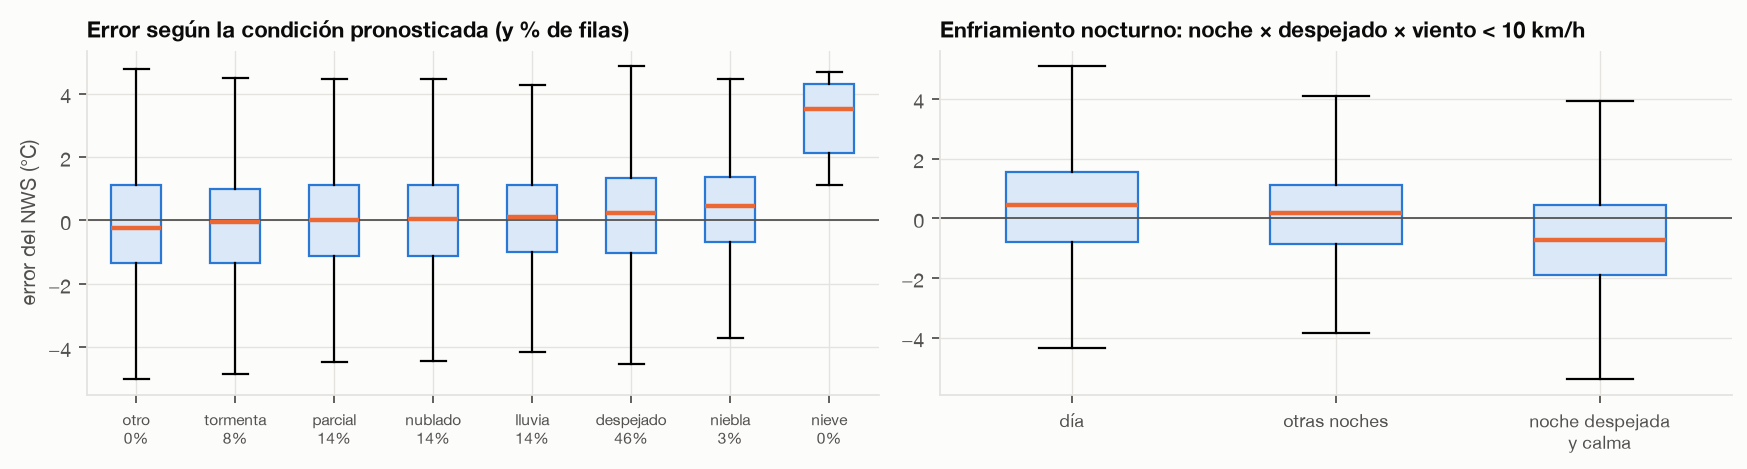

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3))
orden = muestra.groupby("condicion", observed=True)["error_c"].median().sort_values().index
datos_c = [muestra.loc[muestra.condicion == c, "error_c"].to_numpy() for c in orden]
ax[0].boxplot(datos_c, showfliers=False, widths=0.5, patch_artist=True, boxprops=dict(facecolor="#dbe8f7", edgecolor=SERIE[0]),
              medianprops=dict(color=SERIE[1], lw=2))
ax[0].set_xticks(range(1, len(orden) + 1), [f"{c}\n{(muestra.condicion == c).mean():.0%}" for c in orden], fontsize=7)
ax[0].set(ylabel="error del NWS (°C)", title="Error según la condición pronosticada (y % de filas)")
cl = muestra.assign(grupo=np.select([muestra.noche & (muestra.condicion == "despejado") & (muestra.viento_vel < 10),
                                     muestra.noche], ["noche despejada\ny calma", "otras noches"], "día"))
g = ["día", "otras noches", "noche despejada\ny calma"]
ax[1].boxplot([cl.loc[cl.grupo == x, "error_c"] for x in g], showfliers=False, widths=0.5, patch_artist=True,
              boxprops=dict(facecolor="#dbe8f7", edgecolor=SERIE[0]), medianprops=dict(color=SERIE[1], lw=2))
ax[1].set_xticks([1, 2, 3], g, fontsize=8)
ax[1].set(title="Enfriamiento nocturno: noche × despejado × viento < 10 km/h")
for a in ax:
    a.axhline(0, color=TXT2, lw=0.8)
fig.tight_layout(); guardar(fig, "exploracion_base_condicion_noche.png")

## 2. Pendiente del pronóstico

Variables: `pendiente_pron`

**Hipótesis experta.** Si la temperatura pronosticada cambia rápido alrededor de la hora objetivo (paso de un frente,
salida o puesta del sol), un error de una hora en el *timing* se convierte en varios grados de error. Además, la
observación se registra unos minutos antes o después de la hora en punto.

**Qué esperamos ver:** errores más grandes, y con signo, cuando la pendiente es fuerte.

,faltantes_pct,todos,1 h,6 h,24 h,48 h
variable,,,,,,
pendiente_pron,0.0,0.336,0.404,0.348,0.338,0.276


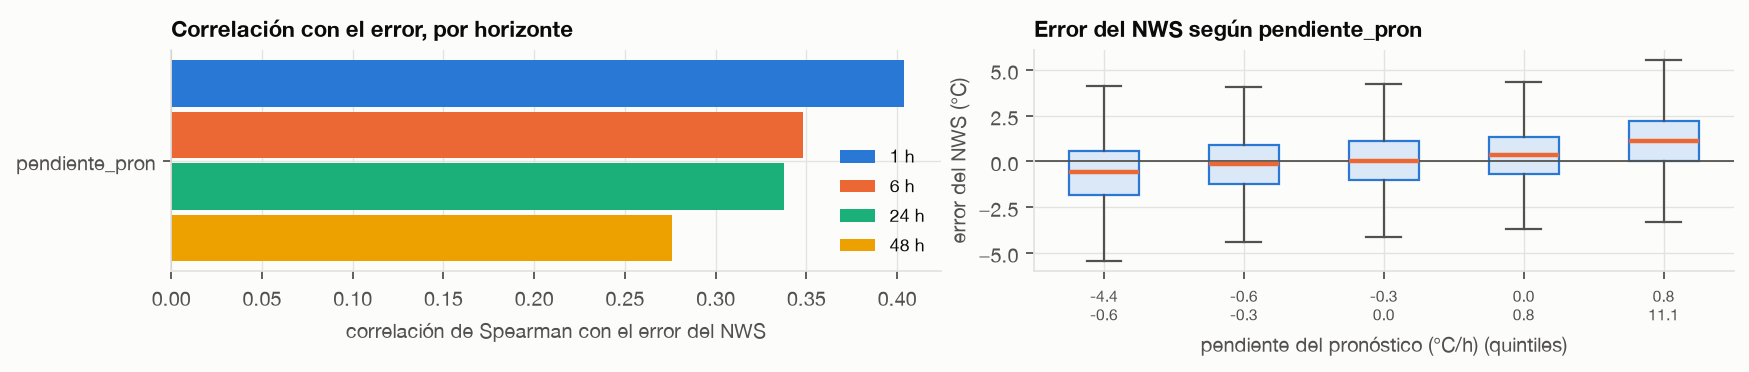

In [5]:
explorar("pendiente", "pendiente_pron", "pendiente del pronóstico (°C/h)")

## 3. Rezagos: últimos errores conocidos

Variables: `err_ult`, `err_media3`, `err_media6`, `err_ayer`

**Hipótesis experta.** El error del pronóstico persiste: si el NWS viene errando para arriba, la situación que lo
provoca suele seguir unas horas. Con nuestros datos, la autocorrelación del error es de 0,84 a 1 h y de 0,19 a 6 h,
con un repunte a 24 h por el ciclo diario (DECISIONES.md, Etapa A).

**Qué esperamos ver:** correlación positiva fuerte en horizontes cortos, que se apaga a 24–48 h.

,faltantes_pct,todos,1 h,6 h,24 h,48 h
variable,,,,,,
err_ult,19.196,0.111,0.477,0.044,0.298,0.240
err_media3,15.422,0.113,0.390,0.008,0.250,0.193
err_media6,12.558,0.117,0.278,-0.030,0.179,0.143
err_ayer,16.612,0.331,0.373,0.380,0.306,0.303


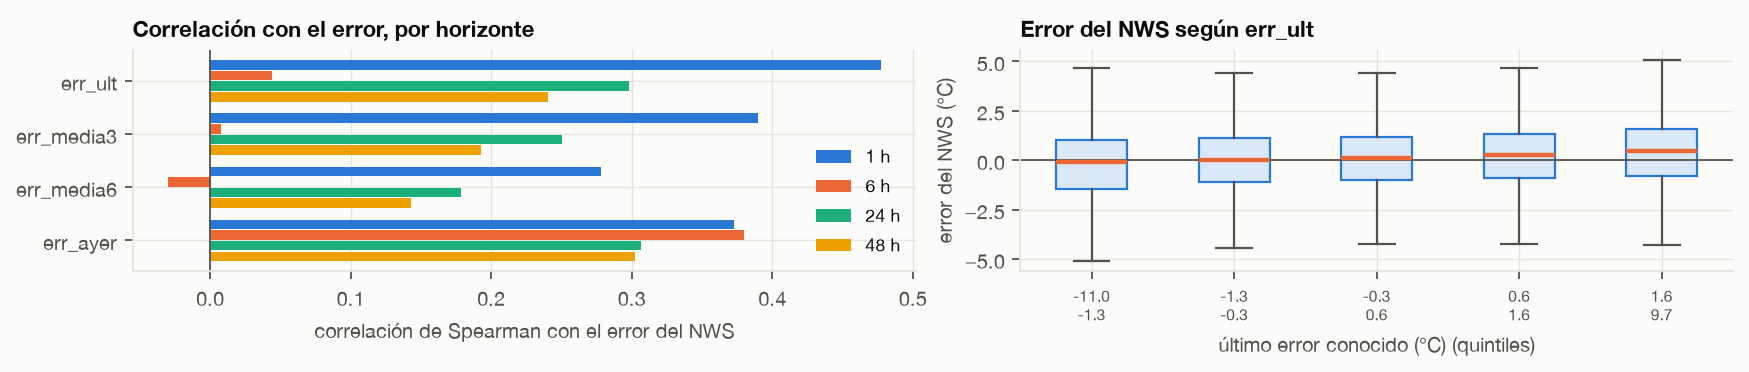

In [6]:
explorar("rezagos", "err_ult", "último error conocido (°C)")

## 4. Sesgo habitual de la estación

Variables: `sesgo_ewma_05`, `sesgo_ewma_10`, `sesgo_ewma_20`, `sesgo_ewma_30`

**Hipótesis experta.** Cada estación tiene un sesgo propio por su entorno (altura, valle, costa, isla de calor) que la
grilla del NWS no resuelve. Es la idea del *decaying average* que el NWS usa en el National Blend of Models: un
promedio de días con más peso a los recientes.

**Qué esperamos ver:** correlación positiva parecida en todos los horizontes (el sesgo no depende de la antelación).

,faltantes_pct,todos,1 h,6 h,24 h,48 h
variable,,,,,,
sesgo_ewma_05,6.401,0.330,0.350,0.339,0.332,0.314
sesgo_ewma_10,6.401,0.361,0.381,0.375,0.363,0.343
sesgo_ewma_20,6.401,0.378,0.397,0.400,0.373,0.355
sesgo_ewma_30,6.401,0.380,0.400,0.409,0.367,0.350


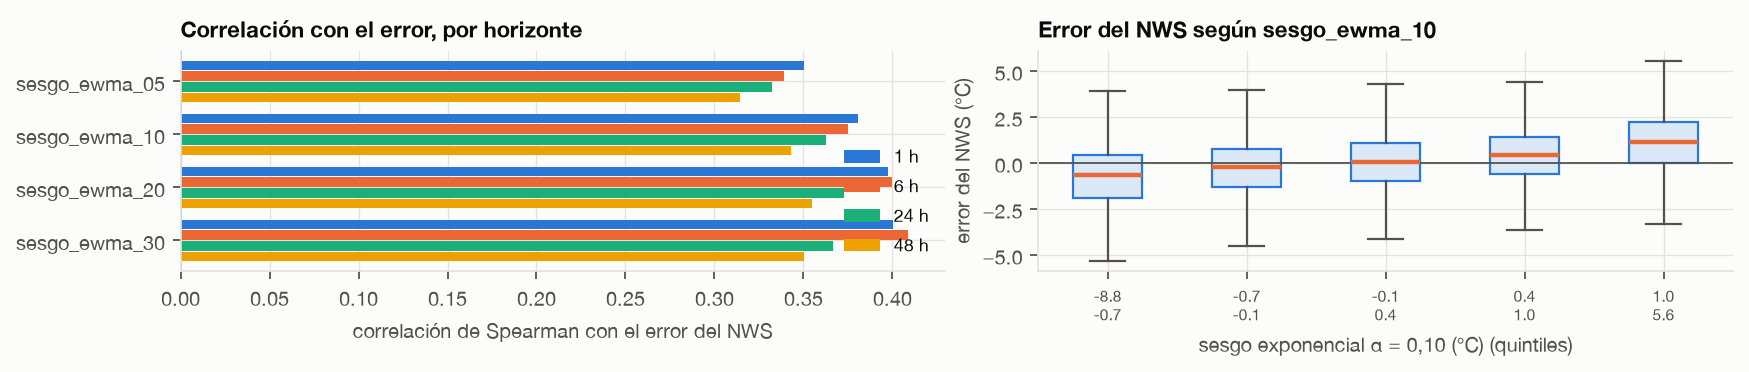

In [7]:
explorar("sesgo_ewma", "sesgo_ewma_10", "sesgo exponencial α = 0,10 (°C)")

## 5. Errores de las estaciones vecinas

Variables: `vec_err_ult`, `vec_err_1h`

**Hipótesis experta.** Un sistema que se desplaza afecta primero a las estaciones cercanas: el error reciente de la
zona podría anticipar el propio, sobre todo cuando falta la historia de la estación.

**Qué esperamos ver:** correlación positiva, en buena parte repetida con los rezagos (en la corrida del 10/11, el
error de las vecinas se correlacionaba 0,67–0,78 con el de la propia estación).

,faltantes_pct,todos,1 h,6 h,24 h,48 h
variable,,,,,,
vec_err_ult,10.046,0.057,0.358,-0.03,0.230,0.185
vec_err_1h,9.807,0.058,0.358,-0.03,0.222,0.177


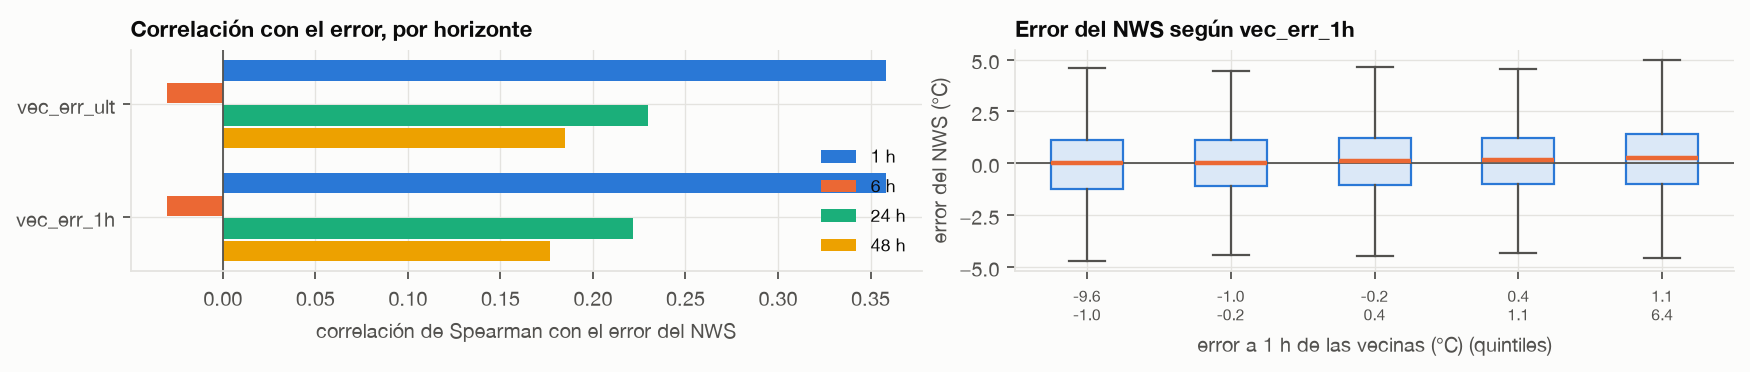

In [8]:
explorar("vecinos", "vec_err_1h", "error a 1 h de las vecinas (°C)")

## 6. Revisión del pronóstico entre emisiones

Variables: `rev_3h`, `rev_6h`, `rev_12h`, `rev_24h`

**Hipótesis experta.** Si el NWS cambió mucho el pronóstico para la misma hora entre una emisión y la siguiente, la
situación es incierta o su modelo se está corrigiendo: la dirección del cambio podría indicar hacia dónde va el error.

**Qué esperamos ver:** relación con el signo del error, más clara cuanto más reciente es la revisión.

,faltantes_pct,todos,1 h,6 h,24 h,48 h
variable,,,,,,
rev_3h,6.708,-0.042,-0.073,-0.091,-0.058,NaN
rev_6h,13.125,-0.062,-0.108,-0.107,-0.088,NaN
rev_12h,25.649,-0.085,-0.121,-0.084,-0.113,NaN
rev_24h,50.709,-0.061,-0.066,-0.063,-0.078,NaN


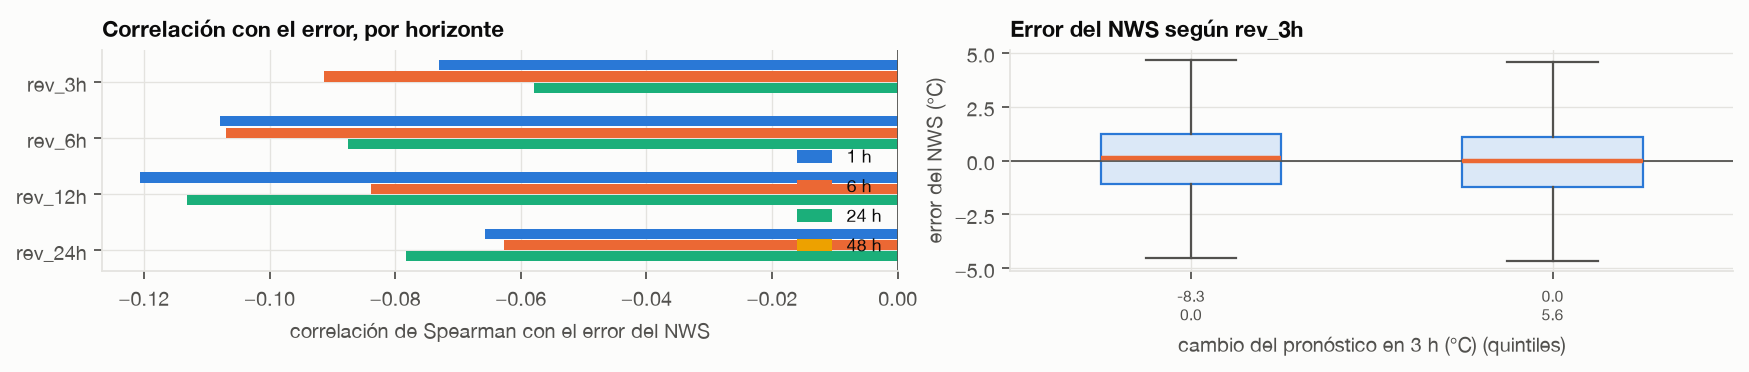

In [9]:
explorar("revision", "rev_3h", "cambio del pronóstico en 3 h (°C)")

## 7. Rezagos extra y error del pronóstico a 1 h

Variables: `err_hace9h`, `err_hace12h`, `err_hace15h`, `err_hace18h`, `err_hace21h`, `err1h_ult`, `err1h_media2`, `err1h_media4`, `err1h_media8`

**Hipótesis experta.** El error del pronóstico a 1 h es lo más fresco que hay («cuánto venimos errando hoy»), y los
rezagos de 9 a 21 h antes de la emisión cubren el ciclo diario del error.

**Qué esperamos ver:** señal fuerte en horizontes cortos, en parte repetida con los rezagos.

,faltantes_pct,todos,1 h,6 h,24 h,48 h
variable,,,,,,
err_hace9h,20.222,0.085,-0.069,-0.030,-0.053,-0.076
err_hace12h,20.680,0.081,-0.088,0.085,-0.103,-0.122
err_hace15h,21.134,0.081,-0.021,0.246,-0.058,-0.059
err_hace18h,21.449,0.076,0.133,0.380,0.040,0.035
err_hace21h,21.963,0.073,0.297,0.222,0.185,0.169
err1h_ult,18.795,0.113,0.477,0.044,0.288,0.215
err1h_media2,11.102,0.114,0.435,0.031,0.271,0.212
err1h_media4,12.138,0.116,0.351,-0.008,0.229,0.170
err1h_media8,12.786,0.120,0.213,-0.045,0.133,0.083


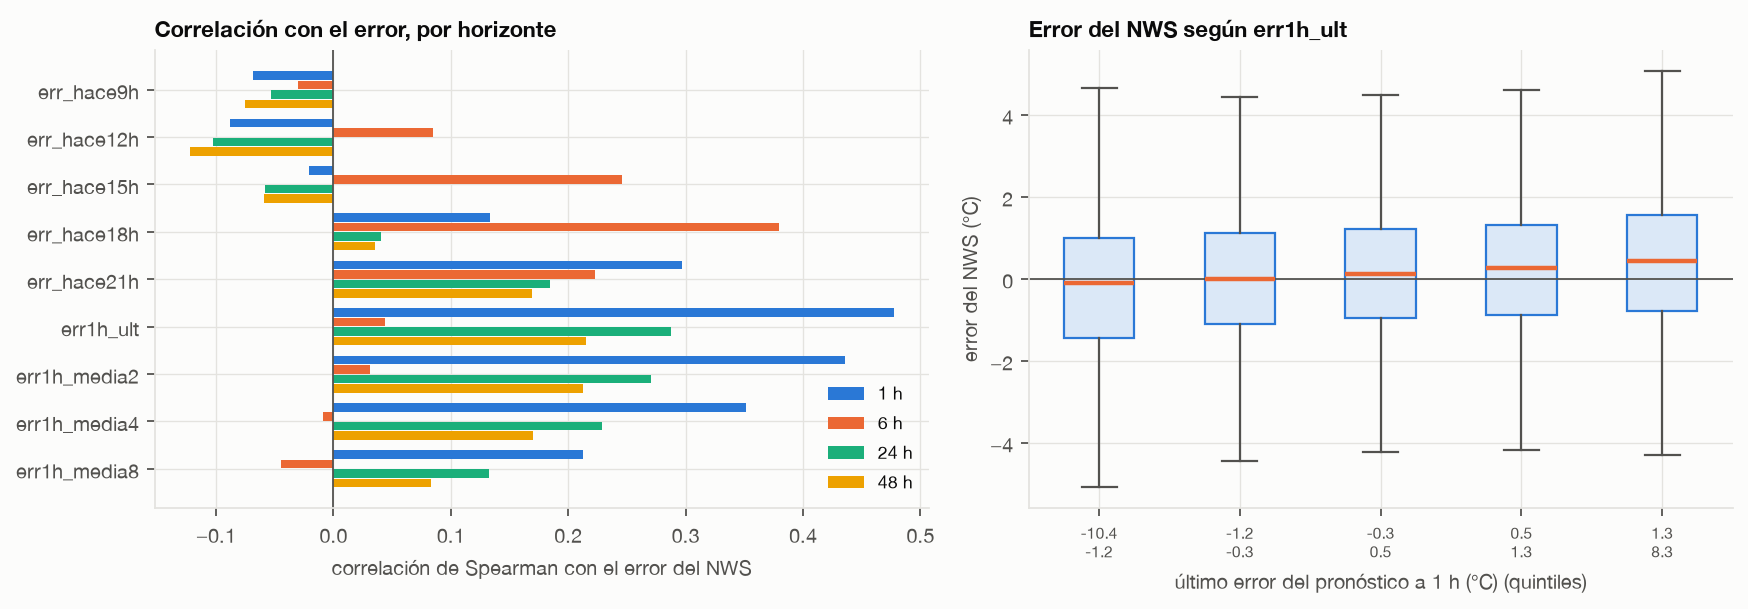

In [10]:
explorar("rezagos_extra", "err1h_ult", "último error del pronóstico a 1 h (°C)")

## 8. Dinámica reciente

Variables: `obs_tend3h`, `err1h_tend3h`, `salto_obs`, `err_rocio_ult`, `err_rocio_1h`, `err_std6`, `err_std24`, `dispersion_emis`, `amplitud_pron`

**Hipótesis experta.** Lo que viene cambiando en las últimas horas dice si el día se aparta de lo previsto: la
tendencia observada frente a la pronosticada, el error en el punto de rocío, la variabilidad reciente del error y
cuánto dudó el NWS entre emisiones.

**Qué esperamos ver:** señal en horizontes cortos; el salto entre el pronóstico y la última observación, con signo.

,faltantes_pct,todos,1 h,6 h,24 h,48 h
variable,,,,,,
obs_tend3h,26.962,0.016,0.135,-0.199,0.110,0.056
err1h_tend3h,27.782,0.015,0.295,0.099,0.158,0.136
salto_obs,18.337,-0.061,-0.055,0.073,0.028,0.093
err_rocio_ult,26.121,0.038,0.126,0.012,0.089,0.075
err_rocio_1h,25.749,0.037,0.126,0.016,0.085,0.081
err_std6,12.558,-0.011,-0.040,-0.083,-0.051,-0.072
err_std24,10.873,-0.030,-0.053,-0.041,-0.034,-0.025
dispersion_emis,4.190,-0.004,-0.022,-0.030,0.003,NaN
amplitud_pron,0.186,-0.041,0.015,-0.014,-0.045,-0.164


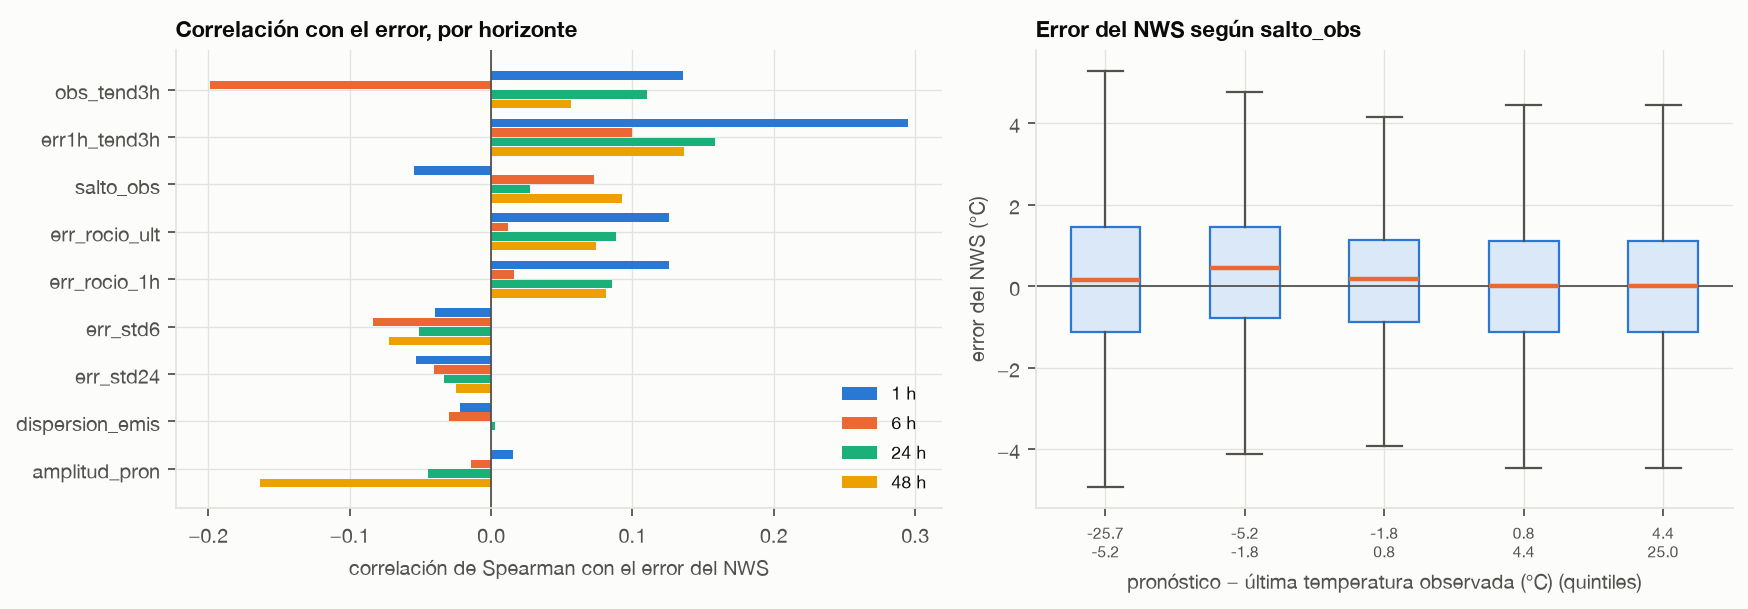

In [11]:
explorar("dinamica", "salto_obs", "pronóstico − última temperatura observada (°C)")

## Mapa de correlaciones y redundancia entre familias

A la izquierda, la correlación de Spearman entre todas las variables numéricas, ordenadas por familia. A la derecha,
para cada par de familias, la **mayor** correlación (en valor absoluto) entre una variable de una y una de la otra.
Un valor cerca de 1 indica que las dos familias repiten información: el Ridge les va a repartir el peso, y la
ablación probablemente muestre que una de las dos sobra. La diagonal es la redundancia **dentro** de la familia
(entre sus propias variables); `pendiente` tiene una sola variable y por eso queda vacía.

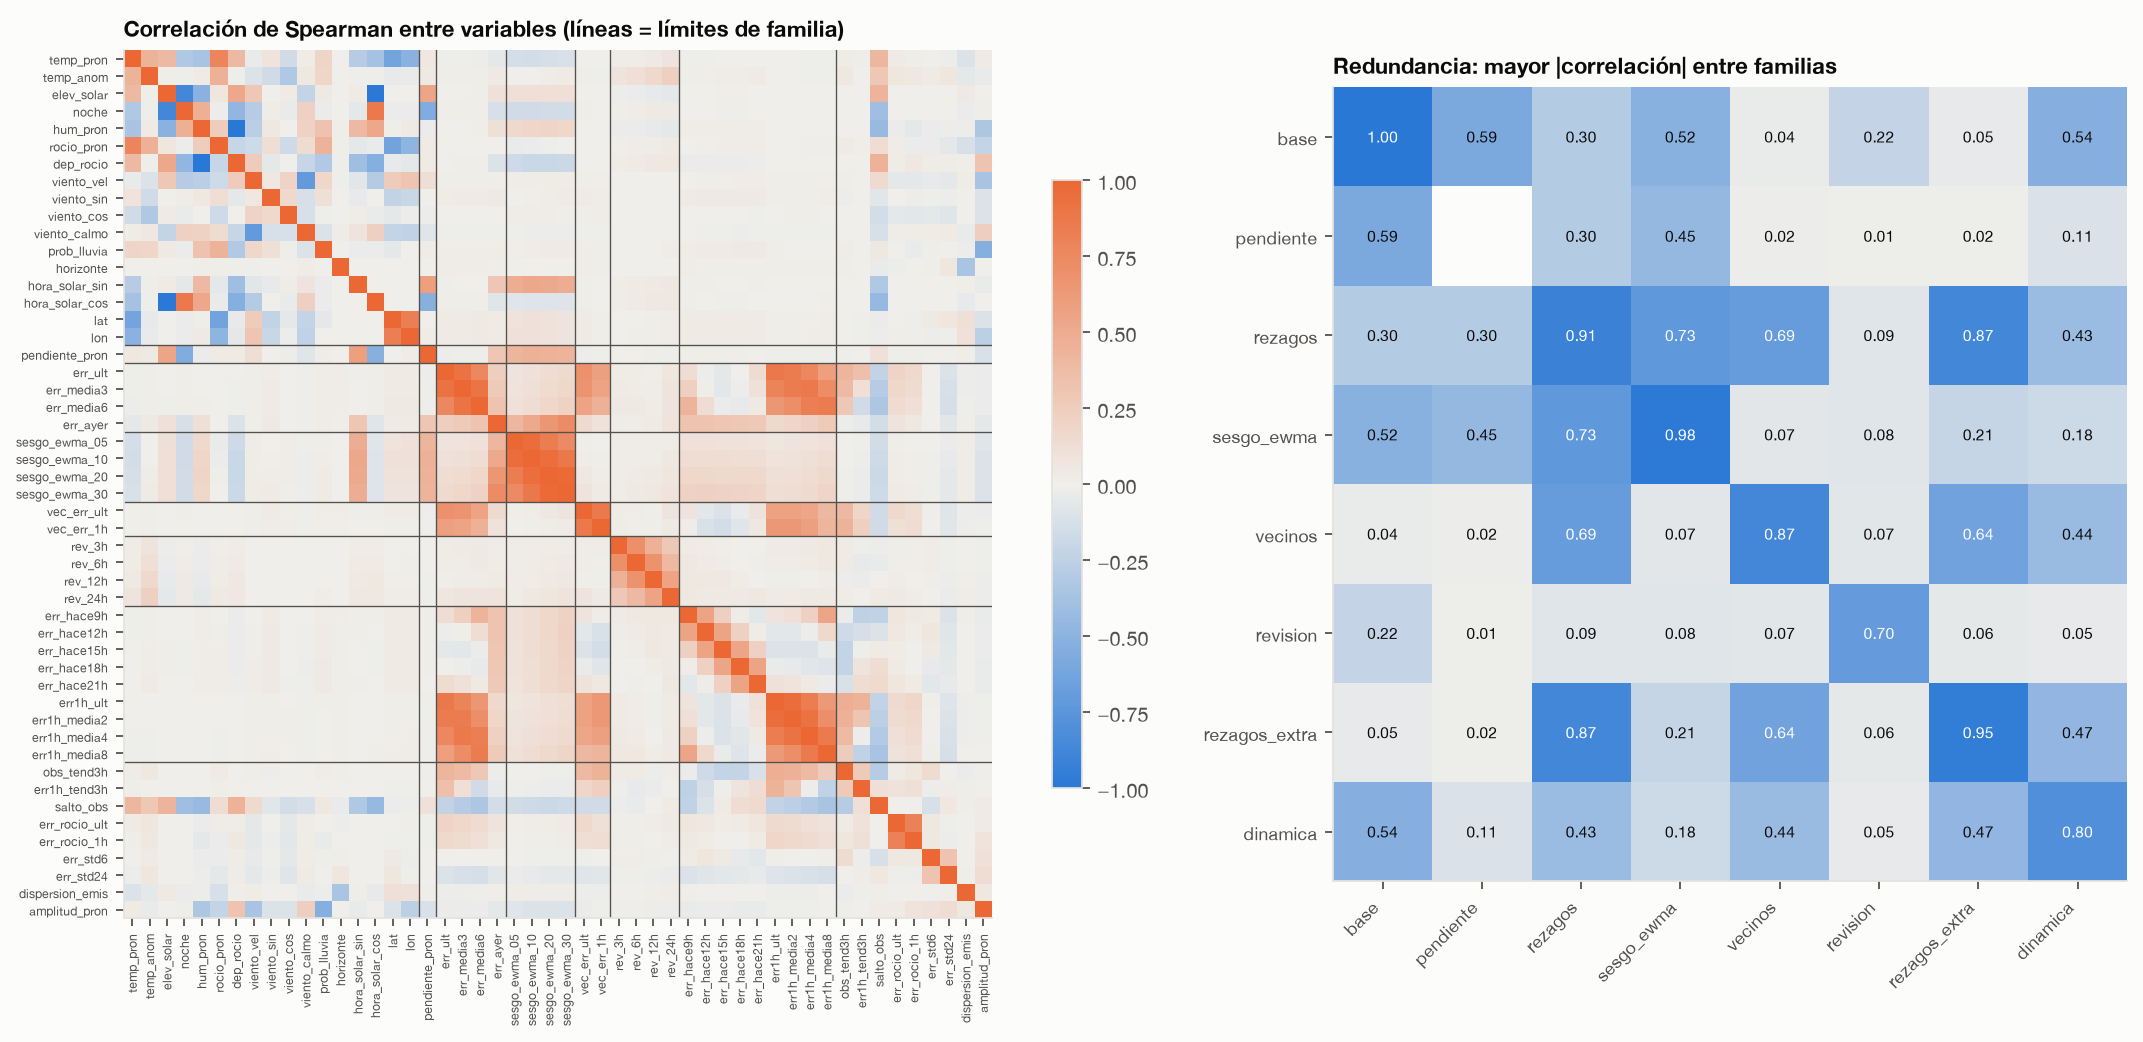

In [12]:
M = E.mapa_correlaciones(muestra)
R = E.redundancia_entre_familias(M)
E.exportar("redundancia_entre_familias", R)
fig, ax = plt.subplots(1, 2, figsize=(14, 6.4), gridspec_kw={"width_ratios": [1.5, 1]})
im = ax[0].imshow(M, cmap=DIVERGENTE, vmin=-1, vmax=1)
ax[0].set_xticks(range(len(M)), M.columns, rotation=90, fontsize=5.5)
ax[0].set_yticks(range(len(M)), M.index, fontsize=5.5)
ax[0].grid(False)
cortes = np.cumsum([sum(c in M.index for c in MI.FAMILIAS[f]) for f in MI.TODAS])[:-1] - 0.5
for c in cortes:
    ax[0].axhline(c, color=TXT2, lw=0.6); ax[0].axvline(c, color=TXT2, lw=0.6)
ax[0].set_title("Correlación de Spearman entre variables (líneas = límites de familia)")
fig.colorbar(im, ax=ax[0], shrink=0.7)
im2 = ax[1].imshow(R.astype(float), cmap=SECUENCIAL, vmin=0, vmax=1)
ax[1].set_xticks(range(8), R.columns, rotation=45, ha="right", fontsize=8)
ax[1].set_yticks(range(8), R.index, fontsize=8)
ax[1].grid(False)
for i in range(8):
    for j in range(8):
        v = R.iloc[i, j]
        if pd.notna(v):
            ax[1].text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=7, color="white" if v > 0.6 else "#0b0b0b")
ax[1].set_title("Redundancia: mayor |correlación| entre familias")
fig.tight_layout(); guardar(fig, "mapa_correlaciones.png")
del muestra

## Ridge con todas las familias

Una matriz XᵀX por pliegue de elección alcanza para todas las variantes: sacar una familia es sacar sus filas y
columnas, con el mismo resultado que reentrenar (`src/ridge_gram.py`, con test de equivalencia contra scikit-learn).
Para cada variante se elige su propio α en una grilla (si queda en un borde, la grilla se amplía).

**Aporte de cada familia:** desvío estándar, en °C, de la parte de la predicción que sale de sus columnas. Se mide por
familia y no columna por columna: columnas parecidas (`err_ult`, `err_media3`, `err_media6`) se reparten el peso, y
mirando cada una sola se subestimaría el grupo. **Estabilidad:** qué porcentaje de los coeficientes de la familia
cambia de signo entre los dos pliegues de elección (si cambian, su efecto no es confiable).

Ridge con todas las familias: α elegido = 1e+05, MAE medio de elección = 1.2460 °C


pliegue,1,2,medio
alpha,,,
1.000e+00,1.312,1.235,1.273
1.000e+02,1.278,1.232,1.255
1.000e+03,1.280,1.230,1.255
1.000e+04,1.275,1.230,1.252
1.000e+05,1.262,1.230,1.246
1.000e+06,1.257,1.255,1.256
1.000e+07,1.307,1.369,1.338


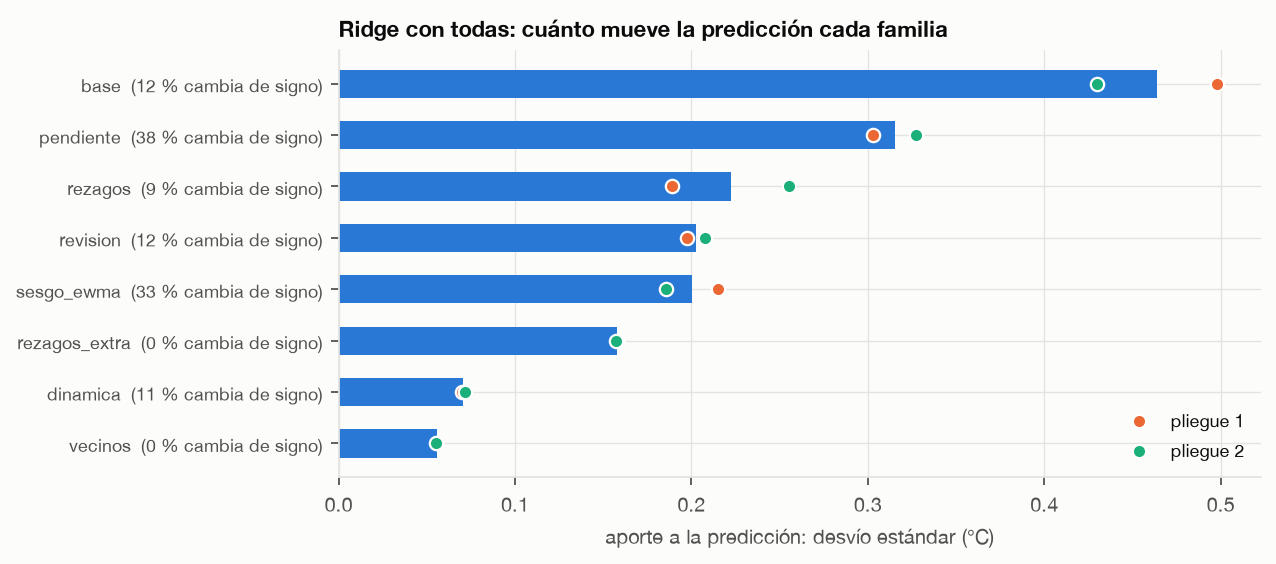

In [13]:
datos = [(k, *E.preparar_gram(k, tr, te)) for k, (tr, te) in eleccion]
tab = E.tabla_variantes(E.variantes_ablacion(), datos)
mejores = E.mejor_por_variante(tab)
E.exportar("ridge_variantes_por_alpha", tab, index=False)
alpha_todas = mejores.loc["todas", "alpha"]
print(f"Ridge con todas las familias: α elegido = {alpha_todas:.0e}, MAE medio de elección = {mejores.loc['todas', 'MAE_medio']:.4f} °C")
display(tab[tab.variante == "todas"].pivot(index="alpha", columns="pliegue", values="MAE").assign(medio=lambda x: x.mean(axis=1)).round(4))
contrib = E.contribuciones_todas(datos, alpha_todas)
E.exportar("aporte_por_familia", contrib, index=False)
orden = contrib.groupby("familia")["aporte_desvio_C"].mean().sort_values().index
fig, ax = plt.subplots(figsize=(8, 3.6))
media = contrib.groupby("familia")["aporte_desvio_C"].mean().reindex(orden)
ax.barh(range(len(orden)), media, color=SERIE[0], height=0.55)
for j, (k, g) in enumerate(contrib.groupby("pliegue")):
    ax.plot(g.set_index("familia")["aporte_desvio_C"].reindex(orden), range(len(orden)), "o", color=SERIE[1 + j],
            ms=6, label=f"pliegue {k}", markeredgecolor="white")
signo = contrib.groupby("familia")["coef_que_cambian_de_signo_pct"].first().reindex(orden)
ax.set_yticks(range(len(orden)), [f"{f}  ({s:.0f} % cambia de signo)" for f, s in signo.items()], fontsize=8)
ax.set(xlabel="aporte a la predicción: desvío estándar (°C)", title="Ridge con todas: cuánto mueve la predicción cada familia")
ax.legend(loc="lower right", fontsize=8)
fig.tight_layout(); guardar(fig, "aporte_por_familia.png")

## Ablación: el Ridge sin cada familia y la regla

`delta` = MAE sin la familia − MAE con todas (°C), cada variante con su propio α. **Positivo = sin ella el modelo
empeora** (la familia aporta). La columna `se_saca` aplica la regla: delta promedio ≤ 0,005 °C y delta en cada
pliegue ≤ 0,010 °C.

,alpha_sin,delta_promedio,delta_max,delta_pliegue_1,delta_pliegue_2,se_saca
familia,,,,,,
base,100000.0,1.680e-02,3.440e-02,-9.000e-04,3.440e-02,False
pendiente,100000.0,6.100e-03,7.200e-03,4.900e-03,7.200e-03,False
rezagos,100000.0,6.200e-03,6.500e-03,5.900e-03,6.500e-03,False
sesgo_ewma,100000.0,1.530e-02,2.170e-02,8.800e-03,2.170e-02,False
vecinos,100000.0,-6.000e-04,-5.000e-04,-8.000e-04,-5.000e-04,True
revision,100000.0,2.000e-03,1.360e-02,-9.500e-03,1.360e-02,False
rezagos_extra,100000.0,2.200e-03,3.000e-03,3.000e-03,1.400e-03,True
dinamica,100000.0,-9.000e-04,-9.000e-04,-9.000e-04,-9.000e-04,True


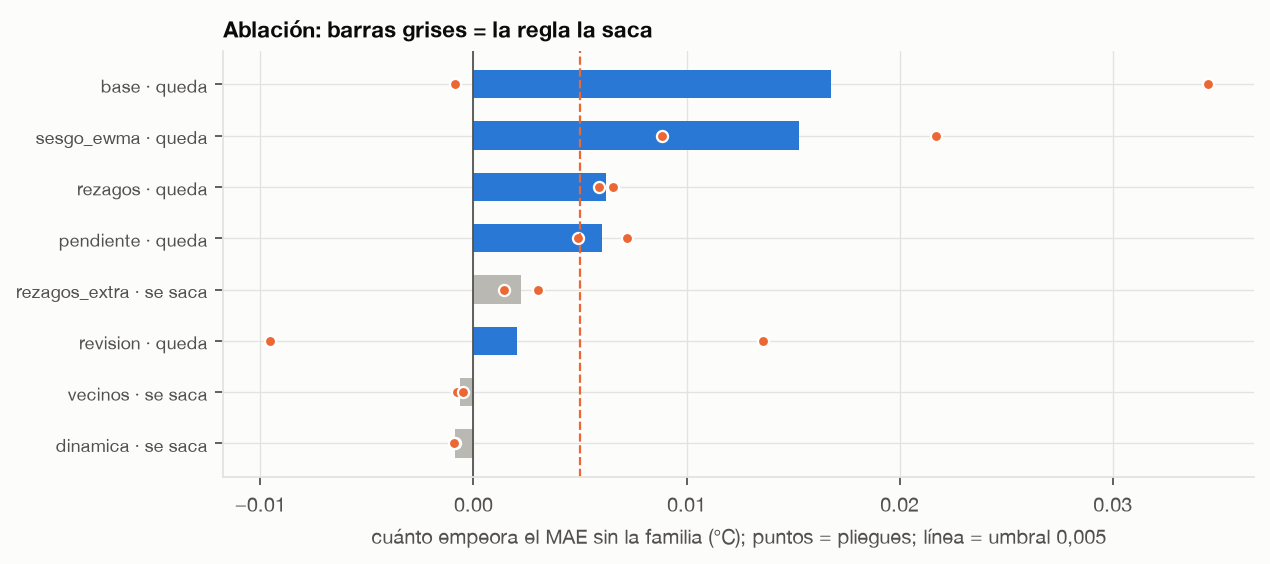

La regla saca, una por una: ['vecinos', 'rezagos_extra', 'dinamica']
Recorte confirmado (sacándolas juntas): ['vecinos', 'rezagos_extra', 'dinamica']


In [14]:
abl = E.ablacion(mejores)
E.exportar("ablacion", abl)
display(abl.round(4))
fig, ax = plt.subplots(figsize=(8, 3.6))
o = abl.sort_values("delta_promedio").index
ax.barh(range(len(o)), abl.loc[o, "delta_promedio"], color=[SERIE[0] if not s else "#b9b8b3" for s in abl.loc[o, "se_saca"]], height=0.55)
for c in [c for c in abl.columns if c.startswith("delta_pliegue_")]:
    ax.plot(abl.loc[o, c], range(len(o)), "o", color=SERIE[1], ms=5, markeredgecolor="white")
ax.axvline(E.CFG_E["umbral_promedio_c"], color=SERIE[1], lw=1, ls="--")
ax.axvline(0, color=TXT2, lw=0.8)
ax.set_yticks(range(len(o)), [f"{f} · {'se saca' if abl.loc[f, 'se_saca'] else 'queda'}" for f in o], fontsize=8)
ax.set(xlabel="cuánto empeora el MAE sin la familia (°C); puntos = pliegues; línea = umbral 0,005",
       title="Ablación: barras grises = la regla la saca")
fig.tight_layout(); guardar(fig, "ablacion.png")


def empeoramiento(sacar):
    v = {"todas": MI.TODAS, "recorte": [f for f in MI.TODAS if f not in sacar]}
    m = E.mejor_por_variante(E.tabla_variantes(v, datos))
    return m.loc["recorte", "MAE_medio"] - m.loc["todas", "MAE_medio"]


a_sacar = list(abl.index[abl.se_saca])
recorte = E.confirmar_recorte(a_sacar, abl["delta_promedio"].to_dict(), empeoramiento)
print("La regla saca, una por una:", a_sacar or "ninguna")
print("Recorte confirmado (sacándolas juntas):", recorte or "ninguna")

## Apartarse de la regla (solo con la razón escrita)

Vacío por defecto. Para apartarse: `{"familia": ("queda" | "sale", "razón")}`. Queda registrado en la salida.

In [15]:
APARTARSE_DE_LA_REGLA = {}

familias_final = [f for f in MI.TODAS if f not in recorte]
for f, (decision, razon) in APARTARSE_DE_LA_REGLA.items():
    print(f"Se aparta de la regla: {f} {decision}. Razón: {razon}")
    familias_final = [x for x in familias_final if x != f] + ([f] if decision == "queda" else [])
familias_final = [f for f in MI.TODAS if f in familias_final]

## Resultado

La lista de familias del Ridge final y el MAE de las variantes en los pliegues de elección, por horizonte y por
segmento. Esta lista va a `config.yaml` (`modelos.interpretable.familias`) y con ella se entrena el modelo final.

In [16]:
v_final = E.mejor_por_variante(E.tabla_variantes({"final": familias_final}, datos))
alpha_final = v_final.loc["final", "alpha"]
detalle = E.evaluar_detalle({"Ridge con todas": (MI.TODAS, alpha_todas), "Ridge final": (familias_final, alpha_final)}, datos)
E.exportar("detalle_variantes", detalle, index=False)
E.exportar("familias_ridge_final", pd.DataFrame({"familia": MI.TODAS, "en_el_ridge_final": [f in familias_final for f in MI.TODAS]}),
           index=False)
t = (detalle[detalle.segmento == "completa"].astype({"horizonte": str})
     .groupby(["horizonte", "modelo"])["MAE"].mean().unstack()
     .reindex(["todos", "1", "3", "6", "12", "24", "48"])[["B0", "B2", "Ridge con todas", "Ridge final"]])
print(f"Ridge final: {', '.join(familias_final)} (α = {alpha_final:.0e})")
print(f"Sale(n): {', '.join(f for f in MI.TODAS if f not in familias_final) or 'ninguna'}")
print("MAE (°C), pliegues de elección, días con historia completa:")
display(t.round(3))

Ridge final: base, pendiente, rezagos, sesgo_ewma, revision (α = 1e+05)
Sale(n): vecinos, rezagos_extra, dinamica
MAE (°C), pliegues de elección, días con historia completa:


modelo,B0,B2,Ridge con todas,Ridge final
horizonte,,,,
todos,1.447,1.366,1.246,1.247
1,1.336,1.265,1.008,1.012
3,1.353,1.275,1.090,1.092
6,1.367,1.289,1.139,1.141
12,1.384,1.307,1.179,1.182
24,1.455,1.373,1.261,1.259
48,1.561,1.464,1.388,1.389
